## **Exchange Rate pre-processing**

This jupyter notebook is used to pre-process data on exchange rates.

Following part is relevant to both CZK/EUR and CZK/USD codes.

In [2]:
# Importing packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

### **EUR/CZK**

In [56]:
# Data load
eur_czk = pd.read_excel("/Users/jachymsvejda/Documents/GitHub/FIRE_Rule_from_a_Perspective_of_a_Czech_Retail_Investor/data/exchange_rates/EUR_CZK_old.xlsx")

In [57]:
# Get rid of first row
eur_czk.drop(index=eur_czk.index[0], axis=0, inplace=True)

In [58]:
# Data in ascending order by year
eur_czk = eur_czk.sort_values(by="Date").reset_index().drop("index", axis=1)

In [59]:
# Fill the column Returns will yearly returns in percentages
eur_czk["Returns"] = np.nan
for i in range(1,len(eur_czk)):
    eur_czk.loc[i, "Returns"] = np.round((eur_czk.loc[i, "EURCZK= (BID)"] - eur_czk.loc[i-1, "EURCZK= (BID)"]) / eur_czk.loc[i-1, "EURCZK= (BID)"], 4)

In [61]:
# Export back to Excel
eur_czk.to_excel("/Users/jachymsvejda/Documents/GitHub/FIRE_Rule_from_a_Perspective_of_a_Czech_Retail_Investor/data/exchange_rates/EUR_CZK.xlsx")

In [62]:
# Calculate mean and standard deviation of EUR/CZK Returns
EUR_mean = np.mean(eur_czk["Returns"])
EUR_var = np.var(eur_czk["Returns"])
print(f"The average is {EUR_mean} and the variance is {EUR_var}")

The average is -0.013096153846153848 and the variance is 0.0013832642159763316


<function matplotlib.pyplot.show(close=None, block=None)>

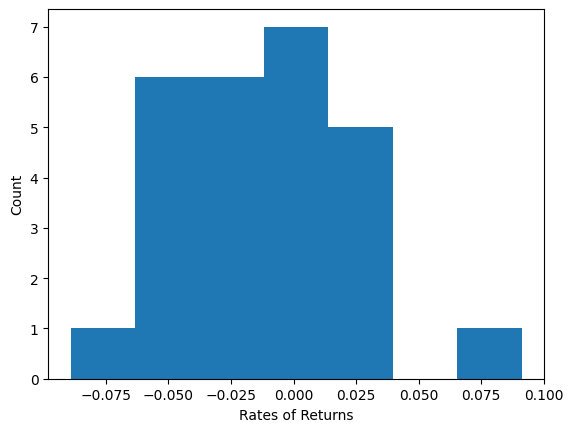

In [63]:
# Create histogram of EUR/CZK Returns
plt.hist(eur_czk["Returns"], bins=7)
plt.xlabel("Rates of Returns")
plt.ylabel("Count")
plt.show
#plt.savefig("/Users/jachymsvejda/Documents/GitHub/FIRE_Rule_from_a_Perspective_of_a_Czech_Retail_Investor/Visualizations/Exchange rate/EUR_hist.pdf", format="pdf", bbox_inches="tight")

### **USD/CZK**

In [37]:
# Data Load
usd_czk = pd.read_excel("/Users/jachymsvejda/Documents/GitHub/FIRE_Rule_from_a_Perspective_of_a_Czech_Retail_Investor/data/exchange_rates/USD_CZK_old.xlsx")

In [39]:
# Transfer column Date to have date format and restrict the data to display only Czech koruna, not Czechoslovak koruna
usd_czk['Date'] = pd.to_datetime(usd_czk['Date'])
usd_czk = usd_czk[usd_czk['Date'] >= '1993-02-08']

In [40]:
# Fill the column Returns will yearly returns in percentages
usd_czk["Returns"] = (
    (usd_czk["CZK= (BID)"] - usd_czk["CZK= (BID)"].shift(-1)) / usd_czk["CZK= (BID)"].shift(-1)
)

/var/folders/zr/40yfwjmx6dqbjgkj5v1_d8r80000gn/T/ipykernel_35250/3693799611.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  usd_czk["Returns"] = (


In [137]:
# Export back to Excel
usd_czk.to_excel("data/exchange_rates/USD_CZK.xlsx")

In [138]:
# Calculate mean and standard deviation of USD/CZK Returns
USD_mean = np.mean(usd_czk["Returns"])
USD_var = np.var(usd_czk["Returns"])
print(f"The Average is {USD_mean} and the variance is {USD_var}")

The Average is -0.0020765268853427314 and the variance is 0.01128739891610039


<function matplotlib.pyplot.show(close=None, block=None)>

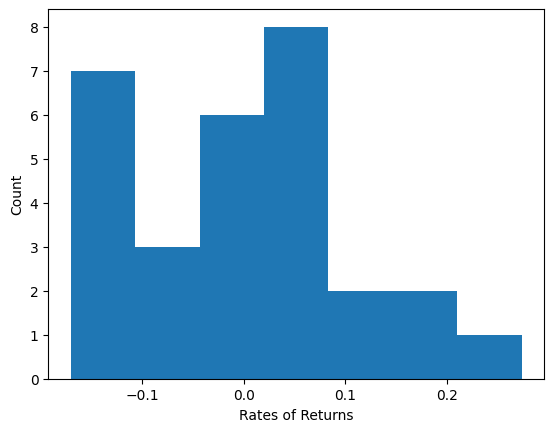

In [139]:
# Create histogram of USD/CZK Returns
plt.hist(usd_czk["Returns"], bins=7)
plt.xlabel("Rates of Returns")
plt.ylabel("Count")
plt.show
#plt.savefig("USD_hist.pdf", format="pdf", bbox_inches="tight")

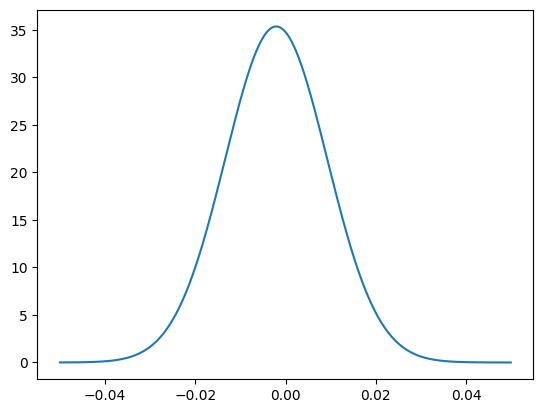

In [140]:
# Plot between -10 and 10 with .001 steps.
x_axis = np.arange(-0.05, 0.05, 0.0001)
# Mean = 0, SD = 2.
plt.plot(x_axis, norm.pdf(x_axis,USD_mean,USD_var))
plt.show()